# Section 1.3 - Data Pre-processing

**TODO**

Data Pre-processing.
1. Perform correlation analysis and visualization through PCA. If you think it could improve the tasks solution, you can do dimensionality reduction for generating the features used in the next tasks.
2. Evaluate if you need to scale or standardize data, and if you need perform label encoding (e.g., one-hot) on some features. If you choose to do so, explain why.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('ddos_dataset_pre_PCA.csv', dtype={'SimillarHTTP':str}, index_col=0)
df.columns = df.columns.str.strip()

In [2]:

df.columns.to_series().groupby(df.dtypes).groups

{int64: ['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'SYN Flag Count', 'RST Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'Subflow Fwd Bytes', 'Subflow Bwd Bytes', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Inbound', 'src_port_category', 'dst_port_category', 'private_src_ip', 'private_dst_ip', 'hour', 'day_of_week'], float64: ['Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Me

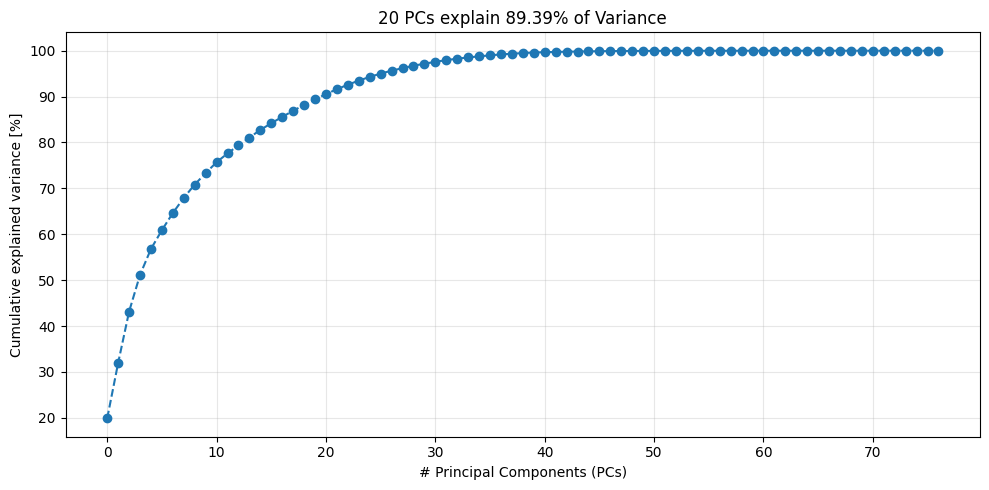

In [ ]:
from sklearn.decomposition import PCA

# saving labels
if 'label' in df.columns:
    y_pca = df['label']
    # Columns to drop (Metadata + Label)
    to_drop = ['Flow ID', 'Source IP', 'Destination IP', 'label', 'Timestamp']
    X_pca = df.drop(columns=to_drop, errors='ignore')
else:
    X_pca = df.copy()
    y_pca = df['label']

cols = X_pca.columns

# SCALING Mandatory for PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

# 3. PCA COMPUTATION
pca = PCA(random_state=15)
pca.fit(X_scaled)

# 4. SCREE PLOT (Variance Explained)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(10, 5))
plt.plot(perc_cumul_exp_var, marker='o', linestyle='--')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
plt.title(f'20 PCs explain {round(perc_cumul_exp_var[19], 2)}% of Variance')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Section 1.4 - Showing Changes

**TODO**

Characterize the new final feature matrix, by producing plots regarding distributions of features (EPDF or ECDF), and correlation analysis.

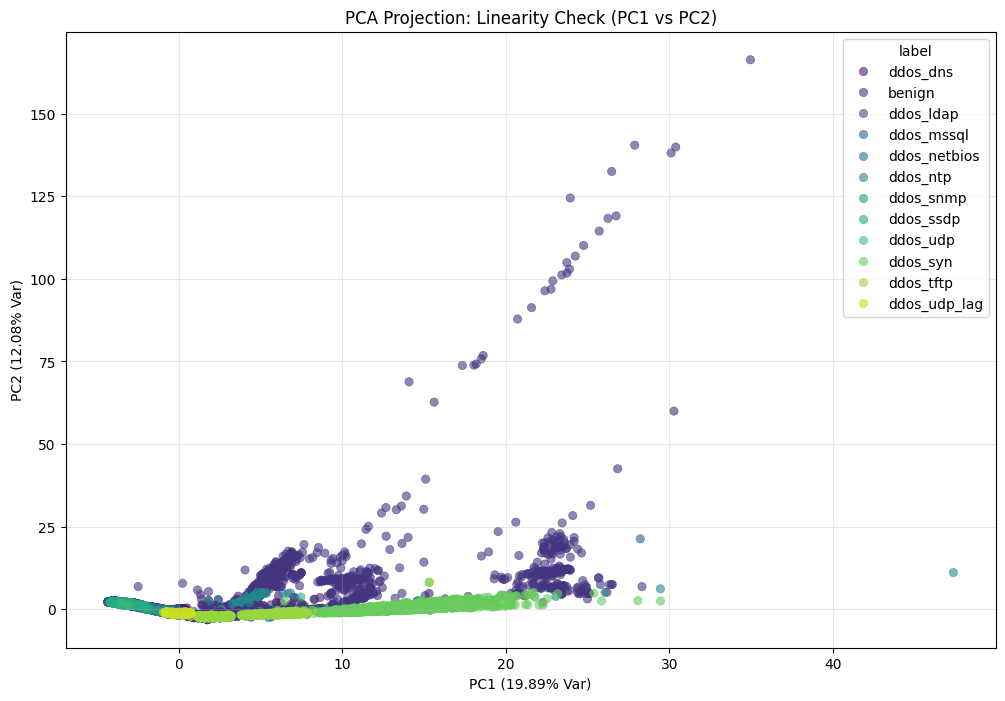

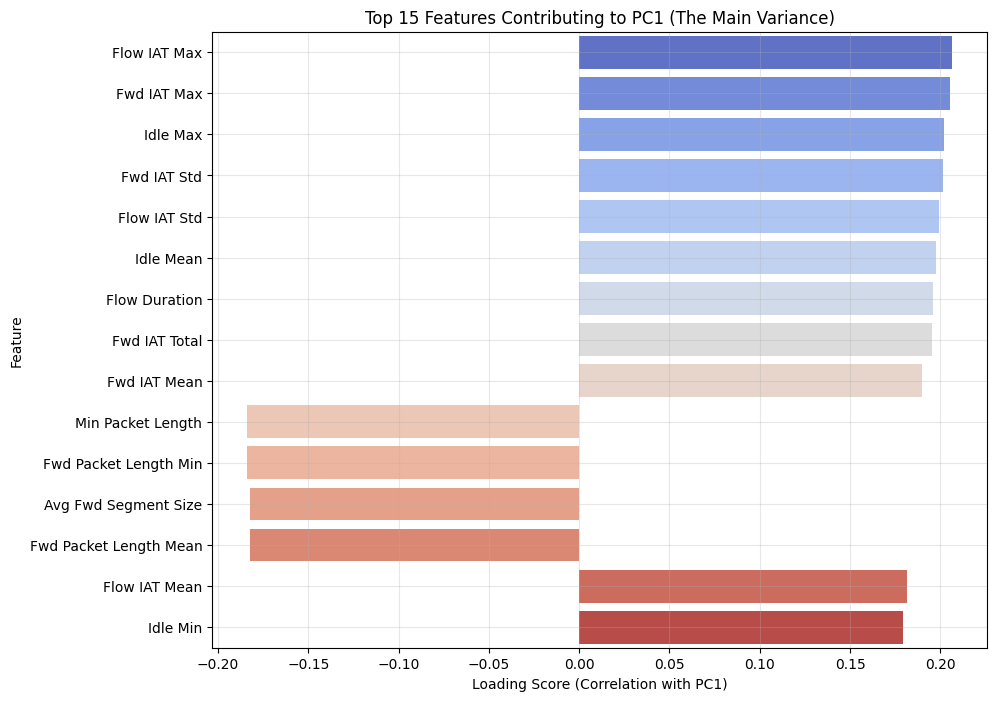

In [ ]:
# SCATTERPLOT (PC1 vs PC2)
# We need to transform the data to get the coordinates
X_transformed = pca.transform(X_scaled)

pca_df = pd.DataFrame(X_transformed[:, :2], columns=['PC1', 'PC2'])
pca_df['label'] = y_pca.values

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=pca_df, x='PC1', y='PC2', hue='label', 
    alpha=0.6, palette='viridis', edgecolor=None
)
plt.title('PCA Projection: Linearity Check (PC1 vs PC2)')
plt.xlabel(f'PC1 ({round(explained_variance[0]*100, 2)}% Var)')
plt.ylabel(f'PC2 ({round(explained_variance[1]*100, 2)}% Var)')
plt.grid(True, alpha=0.3)
plt.show()

# Get the loading vector for PC1
pc1_loadings = pca.components_[0] 

# Create a DataFrame to sort them
loadings_df = pd.DataFrame({'Feature': cols, 'Loading': pc1_loadings})
loadings_df['Abs_Loading'] = loadings_df['Loading'].abs()
top_loadings = loadings_df.sort_values('Abs_Loading', ascending=False).head(15)

plt.figure(figsize=(10, 8))
sns.barplot(data=top_loadings, x='Loading', y='Feature', hue='Feature', legend=False, palette='coolwarm')
plt.title('Top 15 Features Contributing to PC1 (The Main Variance)')
plt.xlabel('Loading Score (Correlation with PC1)')
plt.grid(True, alpha=0.3)
plt.show()

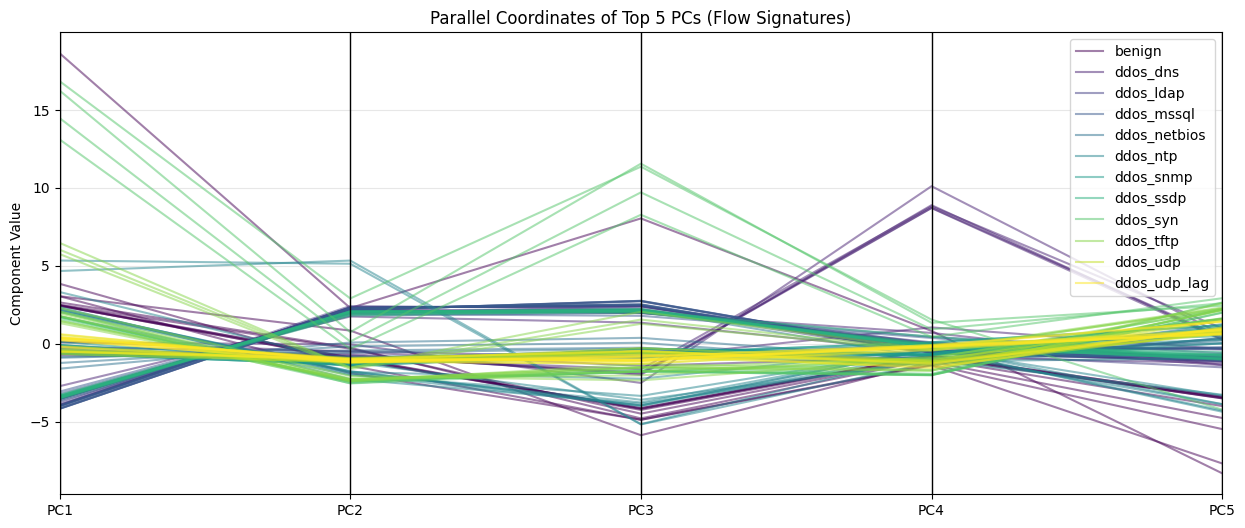

In [5]:
from pandas.plotting import parallel_coordinates

# Create a dataframe with top 5 PCs and the label
# Assuming X_transformed is your PCA output and y_pca is your label series
cols = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
pc_df = pd.DataFrame(X_transformed[:, :5], columns=cols)
pc_df['label'] = y_pca.values


# We take 100 random samples per class to keep it clean.
sampled_pc_df = pc_df.groupby('label').apply(lambda x: x.sample(min(len(x), 10))).reset_index(drop=True)

plt.figure(figsize=(15, 6))
parallel_coordinates(sampled_pc_df, 'label', colormap='viridis', alpha=0.5)
plt.title('Parallel Coordinates of Top 5 PCs (Flow Signatures)')
plt.ylabel('Component Value')
plt.grid(True, alpha=0.3)
plt.show()